# Reproduction of Table 1 of LLM-A* with GPT-4o mini

Reproduction of **Table 1** of *LLM-A\*: Large Language Model Enhanced Incremental Heuristic Search on Path Planning* (Meng et al., arXiv:2407.02511v2) on the 50 × 30 dataset (1000 samples).

* **Methods:** A\*, Dynamic WA\*, LLM-only, LLM-A\* (original code in `llm-astar/`, unchanged)
* **Prompts:** Few-Shot, CoT, RePE
* **LLM:** `gpt-4o-mini-2024-07-18`, temperature 0, max. 1000 tokens, no stop sequence

By default the stored answers in `antworten_<prompt>.json` are used (no API key needed). They were generated once with Section 3 (`QUERY_LLM = True`, key from the Colab secret `OPENAI_API_KEY`).

In [1]:
# ---------------------------------------------------------------------------------------- configuration
QUERY_LLM = False        # False: use the stored GPT-4o mini answers (exact reproduction, no API key needed)
                         # True:  ask GPT-4o mini again (needs OPENAI_API_KEY, about 3000 requests)
MODEL = "gpt-4o-mini"    # OpenAI model for all LLM requests
N_THREADS = 8            # parallel API requests (only used if QUERY_LLM = True)

## 1. Setup

Finds the project folder locally or in Colab (Drive, otherwise clone with the Colab secret `GITHUB_TOKEN`).

In [2]:
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "github.com/leomueller5/llm_astar_max.git"


def is_project_dir(path):
    return (path / "llm-astar").is_dir() and (path / "table1_reproduction").is_dir()


def find_project_dir():
    # Return the project folder, or None if it cannot be found.
    candidates = [Path.cwd(), *Path.cwd().parents]
    if IN_COLAB:
        candidates = [Path("/content/llm_astar_max")] + candidates
    return next((c for c in candidates if is_project_dir(c)), None)


if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "openai", "shapely"], check=True)

PROJECT_DIR = find_project_dir()
if PROJECT_DIR is None and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if is_project_dir(Path("/content/drive/MyDrive/llm_astar_max")):
        PROJECT_DIR = Path("/content/drive/MyDrive/llm_astar_max")
    else:
        from google.colab import userdata
        token = userdata.get("GITHUB_TOKEN")
        result = subprocess.run(["git", "clone", "-q", f"https://{token}@{REPO_URL}", "/content/llm_astar_max"],
                                capture_output=True)
        if result.returncode != 0:          # do not print the command: it contains the token
            raise RuntimeError("Cloning the repository failed. Check the Colab secret GITHUB_TOKEN.")
        PROJECT_DIR = Path("/content/llm_astar_max")
assert PROJECT_DIR is not None, "Project folder not found. Open the notebook inside the project folder."

CODE_DIR = PROJECT_DIR / "llm-astar"                 # original LLM-A* code (unchanged)
OUTPUT_DIR = PROJECT_DIR / "table1_reproduction"     # stored LLM answers and all results
sys.path.insert(0, str(CODE_DIR))
print("Project folder:", PROJECT_DIR)

Project folder: .../llm_astar_max


In [3]:
import contextlib
import copy
import heapq
import io
import json
import math
import types
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# placeholders if transformers/torch are missing (only needed for LLaMA, not used here)
placeholders = []
for name in ("transformers", "torch"):
    try:
        __import__(name)
    except ImportError:
        sys.modules[name] = types.ModuleType(name)
        placeholders.append(name)

from llmastar.env.search import plotting
from llmastar.pather import AStar, LLMAStar
from llmastar.pather.llm_a_star.prompt import gpt_prompt
from llmastar.utils import is_lines_collision, list_parse

for name in placeholders:
    del sys.modules[name]

# switch off the animation of the original planners
plotting.Plotting.animation = lambda self, *args, **kwargs: None

PROMPTS = ["standard", "cot", "repe"]
PROMPT_NAMES = {"standard": "Few-Shot", "cot": "CoT", "repe": "RePE"}

## 2. Data

100 maps × 10 start/goal pairs = 1000 samples.

In [4]:
def load_samples(dataset_file):
    # One entry per start/goal pair: {"id": "<map>_<pair>", "query": {...}}.
    with open(dataset_file, encoding="utf-8") as f:
        maps = json.load(f)
    samples = []
    for m in maps:
        for k, (start, goal, _text) in enumerate(m["start_goal"]):
            samples.append({
                "id": f"{m['id']}_{k}",
                "query": {"start": start, "goal": goal, "size": [51, 31],
                          "horizontal_barriers": m["horizontal_barriers"],
                          "vertical_barriers": m["vertical_barriers"],
                          "range_x": m["range_x"], "range_y": m["range_y"]},
            })
    return samples


samples = load_samples(CODE_DIR / "dataset" / "environment_50_30.json")
print(len(samples), "samples")

1000 samples


## 3. LLM answers

Same prompts as the original code. Unlike the original wrapper we use no `stop=["\n"]`, because it cuts the answers after the first line (see Section 8).

In [5]:
def build_prompt(query, prompt_type):
    # The prompt of the original LLM-A* code for one sample.
    return gpt_prompt[prompt_type].format(start=query["start"], goal=query["goal"],
                                          horizontal_barriers=query["horizontal_barriers"],
                                          vertical_barriers=query["vertical_barriers"])


def make_client():
    # OpenAI client; the key comes from the environment or the Colab secret OPENAI_API_KEY.
    from openai import OpenAI
    if not os.environ.get("OPENAI_API_KEY") and IN_COLAB:
        from google.colab import userdata
        os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
    return OpenAI(max_retries=5)


def ask_llm(client, prompt, stop=None):
    # One request with the settings used for Table 1.
    response = client.chat.completions.create(model=MODEL, temperature=0, max_tokens=1000, stop=stop,
                                              messages=[{"role": "user", "content": prompt}])
    return response.choices[0].message.content or ""


def collect_answers(client, prompt_type, samples, answer_file):
    # Ask the LLM for every sample that has no stored answer yet and save the answers regularly.
    answers = json.load(open(answer_file, encoding="utf-8")) if answer_file.exists() else {}
    todo = [s for s in samples if s["id"] not in answers]
    print(f"{prompt_type}: {len(answers)} stored, {len(todo)} to request")

    def work(sample):
        try:
            return sample["id"], ask_llm(client, build_prompt(sample["query"], prompt_type))
        except Exception as error:
            print("  request failed for", sample["id"], ":", error)
            return sample["id"], None

    with ThreadPoolExecutor(max_workers=N_THREADS) as pool:
        for i, (sample_id, text) in enumerate(pool.map(work, todo), 1):
            if text is not None:
                answers[sample_id] = text
            if i % 100 == 0:
                json.dump(answers, open(answer_file, "w", encoding="utf-8"))
    json.dump(answers, open(answer_file, "w", encoding="utf-8"))
    return answers


answers = {}
client = make_client() if QUERY_LLM else None
for pt in PROMPTS:
    answer_file = OUTPUT_DIR / f"antworten_{pt}.json"
    if QUERY_LLM:
        answers[pt] = collect_answers(client, pt, samples, answer_file)
    else:
        answers[pt] = json.load(open(answer_file, encoding="utf-8"))
    print(f"{PROMPT_NAMES[pt]:8s}: {len(answers[pt])} answers")

Few-Shot: 1000 answers
CoT     : 1000 answers
RePE    : 1000 answers


## 4. Methods

* **A\*, LLM-A\*:** original classes; LLM-A\* gets the stored answer via `CachedAnswer`. If the original parser fails, LLM-A\* runs without waypoints.
* **Dynamic WA\*:** `f = g + w·h` with `w = max(1, 2·0.99^n)`, n = expanded states.
* **LLM-only:** the LLM path itself; valid if it starts/ends at start/goal and no segment touches a barrier.

In [6]:
def quiet(func):
    # Run func() without printing (the original planners print every query and result).
    with contextlib.redirect_stdout(io.StringIO()):
        return func()


class CachedAnswer:
    # Replaces the LLM client of LLMAStar and returns a stored answer.
    def __init__(self, answer):
        self.answer = answer

    def ask(self, *args, **kwargs):
        return self.answer


def run_llm_astar(query, prompt_type, answer):
    # Original LLM-A* with a stored LLM answer. Returns (result, parse_failed).
    def run(text):
        planner = LLMAStar(llm="gpt", prompt=prompt_type)
        planner.model = CachedAnswer(text)
        return quiet(lambda: planner.searching(query=copy.deepcopy(query)))
    try:
        return run(answer), False
    except Exception:
        return run(""), True             # answer cannot be parsed -> search without waypoints


class DynamicWAStar(AStar):
    # Dynamic weighted A*: w = max(1, 2 * 0.99^n), n = number of expanded states.
    def weight(self):
        return max(1.0, 2.0 * 0.99 ** len(self.CLOSED))

    def f_value(self, s):
        return self.g[s] + self.weight() * self.heuristic(s)

    def get_neighbor(self, s):
        # called once per expansion -> re-score OPEN with the new weight
        self.OPEN = [(self.f_value(n), n) for _, n in self.OPEN]
        heapq.heapify(self.OPEN)
        return super().get_neighbor(s)


def segment_hits_barrier(p, q, query):
    # True if the straight segment p-q touches a barrier or the map border.
    width, height = query["range_x"][1] - 1, query["range_y"][1] - 1
    walls = [[[h[1], h[0]], [h[2], h[0]]] for h in query["horizontal_barriers"]]
    walls += [[[v[0], v[1]], [v[0], v[2]]] for v in query["vertical_barriers"]]
    walls += [[[0, 0], [width, 0]], [[0, height], [width, height]],
              [[0, 0], [0, height]], [[width, 0], [width, height]]]
    return any(is_lines_collision([p, q], w) for w in walls)


def check_llm_only_path(query, answer):
    # Evaluate the LLM path itself. Returns (valid, length); length is None for invalid paths.
    path = list_parse(answer or "")
    if not isinstance(path, list) or len(path) < 2:
        return False, None
    try:
        path = [(float(p[0]), float(p[1])) for p in path]
    except Exception:
        return False, None
    if list(path[0]) != list(query["start"]) or list(path[-1]) != list(query["goal"]):
        return False, None
    if any(segment_hits_barrier(a, b, query) for a, b in zip(path, path[1:])):
        return False, None
    return True, sum(math.dist(a, b) for a, b in zip(path, path[1:]))

## 5. Run all methods

In [7]:
rows = []
parse_failures = {pt: 0 for pt in PROMPTS}
for i, s in enumerate(samples, 1):
    q = s["query"]
    a = quiet(lambda: AStar().searching(query=copy.deepcopy(q)))
    w = quiet(lambda: DynamicWAStar().searching(query=copy.deepcopy(q)))
    row = {"id": s["id"],
           "astar_op": a["operation"], "astar_st": a["storage"], "astar_len": a["length"],
           "wa_op": w["operation"], "wa_st": w["storage"], "wa_len": w["length"]}
    for pt in PROMPTS:
        answer = answers[pt][s["id"]]
        r, failed = run_llm_astar(q, pt, answer)
        parse_failures[pt] += failed
        valid, length = check_llm_only_path(q, answer)
        row.update({f"{pt}_op": r["operation"], f"{pt}_st": r["storage"], f"{pt}_len": r["length"],
                    f"{pt}_only_valid": valid, f"{pt}_only_len": length})
    rows.append(row)
    if i % 100 == 0:
        print(f"{i} / {len(samples)} samples")

json.dump(rows, open(OUTPUT_DIR / "ergebnisse.json", "w", encoding="utf-8"))
results = pd.DataFrame(rows)
print("Answers the original LLM-A* parser could not process:",
      {PROMPT_NAMES[pt]: n for pt, n in parse_failures.items()})

100 / 1000 samples


200 / 1000 samples


300 / 1000 samples


400 / 1000 samples


500 / 1000 samples


600 / 1000 samples


700 / 1000 samples


800 / 1000 samples


900 / 1000 samples


1000 / 1000 samples
Answers the original LLM-A* parser could not process: {'Few-Shot': 0, 'CoT': 0, 'RePE': 1}


## 6. Table 1

OR, SR, RL: geometric mean of the ratios to A\* in % (as in the paper), with 95 % CI. VPR: share of valid paths. "Worse than A\*": share of samples with more expanded states than A\*.

In [8]:
def ratio_stats(ratios):
    # Geometric mean of ratios in % with 95 % CI (t-interval on the logs) and SD of the ratios.
    r = np.asarray(ratios, dtype=float)
    r = r[np.isfinite(r) & (r > 0)]
    n, logs = len(r), np.log(r)
    half = stats.t.ppf(0.975, n - 1) * logs.std(ddof=1) / np.sqrt(n)
    return dict(mean=100 * np.exp(logs.mean()), ci_low=100 * np.exp(logs.mean() - half),
                ci_high=100 * np.exp(logs.mean() + half), sd=100 * r.std(ddof=1), n=n)


def share_stats(flags):
    # Share of True values in % with a 95 % Wilson interval.
    x = np.asarray(flags, dtype=bool)
    n, p, z = len(x), x.mean(), stats.norm.ppf(0.975)
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return dict(mean=100 * p, ci_low=100 * (centre - half), ci_high=100 * (centre + half),
                sd=100 * x.std(ddof=1), n=n)


df = results
entries = []                                        # (method, prompt, metric, statistics)
entries += [("Dynamic WA*", "-", "OR", ratio_stats(df.wa_op / df.astar_op)),
            ("Dynamic WA*", "-", "SR", ratio_stats(df.wa_st / df.astar_st)),
            ("Dynamic WA*", "-", "RL", ratio_stats(df.wa_len / df.astar_len)),
            ("Dynamic WA*", "-", "VPR", share_stats(np.isfinite(df.wa_len))),
            ("Dynamic WA*", "-", "Worse than A*", share_stats(df.wa_op > df.astar_op))]
for pt in PROMPTS:
    valid = df[f"{pt}_only_valid"].astype(bool)
    entries += [("LLM-only", PROMPT_NAMES[pt], "RL",
                 ratio_stats(df.loc[valid, f"{pt}_only_len"] / df.loc[valid, "astar_len"])),
                ("LLM-only", PROMPT_NAMES[pt], "VPR", share_stats(valid))]
for pt in PROMPTS:
    entries += [("LLM-A*", PROMPT_NAMES[pt], "OR", ratio_stats(df[f"{pt}_op"] / df.astar_op)),
                ("LLM-A*", PROMPT_NAMES[pt], "SR", ratio_stats(df[f"{pt}_st"] / df.astar_st)),
                ("LLM-A*", PROMPT_NAMES[pt], "RL", ratio_stats(df[f"{pt}_len"] / df.astar_len)),
                ("LLM-A*", PROMPT_NAMES[pt], "VPR", share_stats(np.isfinite(df[f"{pt}_len"]))),
                ("LLM-A*", PROMPT_NAMES[pt], "Worse than A*", share_stats(df[f"{pt}_op"] > df.astar_op))]

statistics = pd.DataFrame([{"Method": m, "Prompt": p, "Metric": k, **st} for m, p, k, st in entries])

METRICS = ["OR", "SR", "RL", "VPR", "Worse than A*"]
table1 = statistics.pivot_table(index=["Method", "Prompt"], columns="Metric", values="mean", sort=False)
table1 = table1.reindex(columns=METRICS)
astar_row = pd.DataFrame([[100, 100, 100, 100, np.nan]], columns=METRICS,
                         index=pd.MultiIndex.from_tuples([("A*", "-")], names=["Method", "Prompt"]))
table1 = pd.concat([astar_row, table1]).round(2)

with_ci = statistics.assign(text=statistics.apply(
    lambda r: f"{r['mean']:.2f} [{r.ci_low:.2f}, {r.ci_high:.2f}]", axis=1))
with_ci = with_ci.pivot_table(index=["Method", "Prompt"], columns="Metric", values="text",
                              aggfunc="first", sort=False).reindex(columns=METRICS).fillna("-")

table1.to_csv(OUTPUT_DIR / "table1_new.csv")
statistics.round(2).to_csv(OUTPUT_DIR / "table1_with_statistics_new.csv", index=False)
with_ci.to_csv(OUTPUT_DIR / "table1_with_ci_new.csv")

print("Table 1 (GPT-4o mini, 1000 samples). OR/SR/RL: geometric mean in % of A*; VPR and 'worse than A*': %.")
print(table1.fillna("-").to_string())
print("\nWith 95 % confidence intervals:")
print(with_ci.to_string())

Table 1 (GPT-4o mini, 1000 samples). OR/SR/RL: geometric mean in % of A*; VPR and 'worse than A*': %.
                         OR     SR      RL    VPR Worse than A*
Method      Prompt                                             
A*          -         100.0  100.0  100.00  100.0             -
Dynamic WA* -          60.9  78.52  100.24  100.0          60.4
LLM-only    Few-Shot      -      -  119.38    6.8             -
            CoT           -      -  124.20    6.2             -
            RePE          -      -  117.33    9.9             -
LLM-A*      Few-Shot  46.09   65.4  102.74  100.0          17.3
            CoT       47.61  66.24  102.61  100.0          17.2
            RePE      50.13  68.31  102.30  100.0          19.2

With 95 % confidence intervals:
Metric                                  OR                    SR                       RL                     VPR         Worse than A*
Method      Prompt                                                                       

## 7. Comparison with the paper (GPT-3.5 rows)

In [9]:
PAPER_GPT35 = {   # (method, prompt): (OR, SR, RL, VPR) from Table 1 of arXiv:2407.02511v2
    ("Dynamic WA*", "-"):      (60.91, 78.53, 100.24, 100.0),
    ("LLM-only", "Few-Shot"):  (np.nan, np.nan, 119.38, 12.80),
    ("LLM-only", "CoT"):       (np.nan, np.nan, 151.73, 15.20),
    ("LLM-only", "RePE"):      (np.nan, np.nan, 183.87, 7.80),
    ("LLM-A*", "Few-Shot"):    (57.39, 74.96, 102.44, 100.0),
    ("LLM-A*", "CoT"):         (69.50, 83.65, 102.54, 100.0),
    ("LLM-A*", "RePE"):        (85.47, 96.53, 102.41, 100.0),
}
comparison = []
for (method, prompt), paper_values in PAPER_GPT35.items():
    for metric, paper in zip(["OR", "SR", "RL", "VPR"], paper_values):
        ours = table1.loc[(method, prompt), metric]
        if np.isnan(paper) or np.isnan(ours):
            continue
        comparison.append({"Method": method, "Prompt": prompt, "Metric": metric,
                           "Paper (GPT-3.5)": paper, "Ours (GPT-4o mini)": ours,
                           "Difference": round(ours - paper, 2)})
comparison = pd.DataFrame(comparison)
comparison.to_csv(OUTPUT_DIR / "table1_comparison_paper_new.csv", index=False)
print(comparison.to_string(index=False))

     Method   Prompt Metric  Paper (GPT-3.5)  Ours (GPT-4o mini)  Difference
Dynamic WA*        -     OR            60.91               60.90       -0.01
Dynamic WA*        -     SR            78.53               78.52       -0.01
Dynamic WA*        -     RL           100.24              100.24        0.00
Dynamic WA*        -    VPR           100.00              100.00        0.00
   LLM-only Few-Shot     RL           119.38              119.38        0.00
   LLM-only Few-Shot    VPR            12.80                6.80       -6.00
   LLM-only      CoT     RL           151.73              124.20      -27.53
   LLM-only      CoT    VPR            15.20                6.20       -9.00
   LLM-only     RePE     RL           183.87              117.33      -66.54
   LLM-only     RePE    VPR             7.80                9.90        2.10
     LLM-A* Few-Shot     OR            57.39               46.09      -11.30
     LLM-A* Few-Shot     SR            74.96               65.40       -9.56

## 8. Answers cut after the first line

CoT answers for 100 samples requested again with `stop=["\n"]` (as in the original wrapper).

In [10]:
cut_file = OUTPUT_DIR / "antworten_cot_abgeschnitten.json"
subset = samples[::10]                                   # 100 samples spread over all maps
if QUERY_LLM:
    with ThreadPoolExecutor(max_workers=N_THREADS) as pool:
        cut_answers = dict(pool.map(
            lambda s: (s["id"], ask_llm(client, build_prompt(s["query"], "cot"), stop=["\n"])), subset))
    json.dump(cut_answers, open(cut_file, "w", encoding="utf-8"))
else:
    cut_answers = json.load(open(cut_file, encoding="utf-8"))

by_id = results.set_index("id")
op_cut, op_full, len_cut, len_full, with_path = [], [], [], [], 0
for s in subset:
    answer = cut_answers[s["id"]]
    with_path += "[[" in answer                          # does the cut answer still contain a path?
    r, _ = run_llm_astar(s["query"], "cot", answer)
    b = by_id.loc[s["id"]]
    op_cut.append(r["operation"] / b.astar_op)
    op_full.append(b.cot_op / b.astar_op)
    len_cut.append(r["length"] / b.astar_len)
    len_full.append(b.cot_len / b.astar_len)

print(f"Cut answers that still contain a path: {with_path} of {len(subset)}")
print(f"Operation ratio, cut answers : {ratio_stats(op_cut)['mean']:.2f} %")
print(f"Operation ratio, full answers: {ratio_stats(op_full)['mean']:.2f} %")
print(f"Relative length, cut answers : {ratio_stats(len_cut)['mean']:.2f} %")
print(f"Relative length, full answers: {ratio_stats(len_full)['mean']:.2f} %")
print("Example of a cut answer:", repr(cut_answers[subset[0]['id']]))

Cut answers that still contain a path: 0 of 100
Operation ratio, cut answers : 35.06 %
Operation ratio, full answers: 48.17 %
Relative length, cut answers : 102.63 %
Relative length, full answers: 102.38 %
Example of a cut answer: 'To find a path from the start point [5, 5] to the goal point [20, 20], we need to navigate around the given horizontal and vertical barriers.'


The cut answers contain no waypoints, so LLM-A\* falls back to weighted A\*. Therefore the full answers are used for Table 1.

## 9. Answers with and without waypoints

LLM-A\* split by whether the LLM answer contains intermediate waypoints or only start and goal.

In [11]:
def n_points(answer):
    # number of points in the LLM answer (start and goal included)
    try:
        path = list_parse(answer or "")
    except Exception:
        return 0
    return len(path) if isinstance(path, list) else 0


rows = []
for pt in PROMPTS:
    points = np.array([n_points(answers[pt][sid]) for sid in results.id])
    has_wp = points > 2
    op = (results[f"{pt}_op"] / results.astar_op).values
    rl = (results[f"{pt}_len"] / results.astar_len).values
    rows.append({"Prompt": PROMPT_NAMES[pt], "Mean points": round(points.mean(), 1),
                 "With waypoints": int(has_wp.sum()),
                 "OR with": round(ratio_stats(op[has_wp])["mean"], 2),
                 "RL with": round(ratio_stats(rl[has_wp])["mean"], 2),
                 "Without waypoints": int((~has_wp).sum()),
                 "OR without": round(ratio_stats(op[~has_wp])["mean"], 2),
                 "RL without": round(ratio_stats(rl[~has_wp])["mean"], 2)})
print(pd.DataFrame(rows).to_string(index=False))

  Prompt  Mean points  With waypoints  OR with  RL with  Without waypoints  OR without  RL without
Few-Shot         10.0             917    47.42   102.83                 83       33.61      101.71
     CoT          7.4             972    48.11   102.65                 28       33.13      101.13
    RePE          5.1             929    52.38   102.35                 71       28.26      101.57


## 10. Example

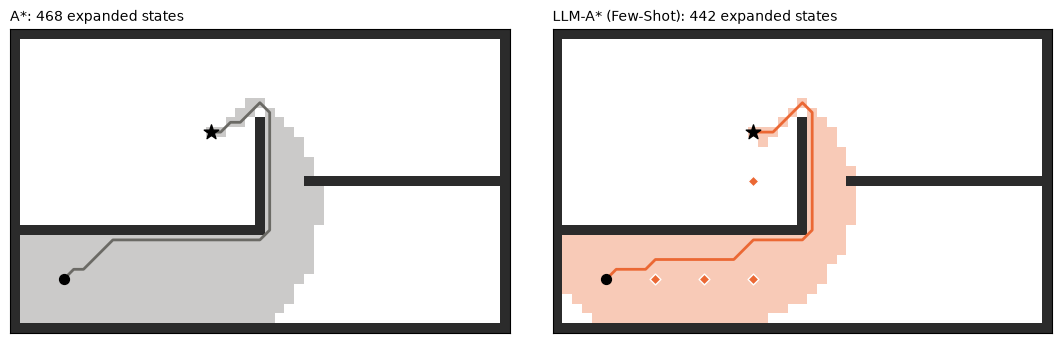

In [12]:
def run_planner(make, query, answer=None):
    planner = make()
    if answer is not None:
        planner.model = CachedAnswer(answer)
    quiet(lambda: planner.searching(query=copy.deepcopy(query)))
    return planner


def draw(ax, planner, colour, title, waypoints=()):
    width, height = planner.Env.x_range, planner.Env.y_range
    grid = np.ones((height, width, 3))
    for x, y in set(planner.CLOSED):
        grid[y, x] = plt.matplotlib.colors.to_rgb(colour) * np.array(0.35) + 0.65
    for x, y in planner.Env.obs:
        grid[y, x] = 0.17
    ax.imshow(grid, origin="lower", interpolation="nearest")
    path = planner.extract_path(planner.PARENT)
    ax.plot([p[0] for p in path], [p[1] for p in path], color=colour, lw=2)
    if waypoints:
        ax.scatter(*zip(*waypoints), marker="D", s=30, color=colour, edgecolor="white", zorder=3)
    ax.scatter(*planner.s_start, s=50, color="black", zorder=4)
    ax.scatter(*planner.s_goal, marker="*", s=120, color="black", zorder=4)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])


example = samples[0]
astar = run_planner(AStar, example["query"])
llm_astar = run_planner(lambda: LLMAStar(llm="gpt", prompt="standard"), example["query"],
                        answers["standard"][example["id"]])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
draw(axes[0], astar, "#6b6a65", f"A*: {len(astar.CLOSED)} expanded states")
draw(axes[1], llm_astar, "#eb6834", f"LLM-A* (Few-Shot): {len(llm_astar.CLOSED)} expanded states",
     waypoints=llm_astar.target_list[1:-1])
plt.tight_layout()
plt.show()

## 11. Output files

`ergebnisse.json` (per-sample results), `table1_new.csv`, `table1_with_ci_new.csv`, `table1_with_statistics_new.csv`, `table1_comparison_paper_new.csv`.